  # 0. Préparation de l'environnement

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.13.0+cpu
Device : cpu


1. Jeu de données MNIST

MNIST contient 60 000 images d'entraînement et 10 000 images de test de chiffres manuscrits. Chaque image est en niveaux de gris et mesure 28 x 28 pixels.

In [14]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


Batch d'images : torch.Size([128, 1, 28, 28])
Batch de labels : torch.Size([128])
Valeurs des pixels : 0.0 -> 1.0


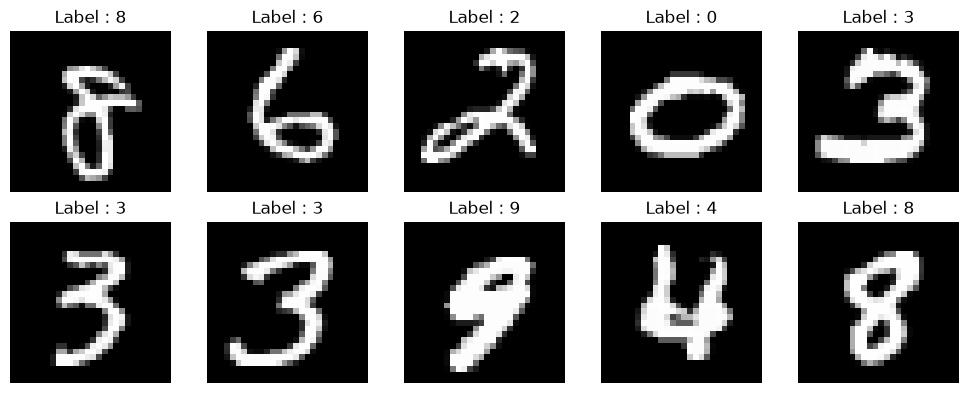

In [15]:
images, labels = next(iter(train_loader))
print("Batch d'images :", images.shape)
print("Batch de labels :", labels.shape)
print("Valeurs des pixels :", float(images.min()), "->", float(images.max()))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for image, label, ax in zip(images[:10], labels[:10], axes.flat):
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"Label : {label.item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Cette cellule servira pour la Partie I : classification.

# Partie I - Modele discriminatif

## 2. Classification : apprendre P(y|x)

Le classifieur recoit une image `x` et predit le chiffre `y`. Il apprend a distinguer les classes 0 a 9, mais il ne genere pas de nouvelles images.

### Etape 1 - Construire le classifieur

`Flatten` transforme chaque image `[1, 28, 28]` en un vecteur de `784` pixels. Les couches `Linear` apprennent ensuite des caracteristiques et produisent 10 scores, un par chiffre.

In [17]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(device)
print(classifier)

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Verification des formes

Cette verification confirme que le modele transforme un lot `[B, 1, 28, 28]` en 10 scores `[B, 10]`.

In [18]:
with torch.no_grad():
    sample_logits = classifier(images[:4].to(device))

print("Entree :", images[:4].shape)
print("Sortie :", sample_logits.shape)
print("Classe predite pour le premier exemple :", sample_logits[0].argmax().item())

Entree : torch.Size([4, 1, 28, 28])
Sortie : torch.Size([4, 10])
Classe predite pour le premier exemple : 9


### Etape 2 - Definir la fonction de perte et l'optimiseur

`CrossEntropyLoss` compare les 10 scores du modele au label correct. `Adam` modifie les poids du reseau pour reduire cette erreur.

In [19]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

### Etape 3 - Entrainement

A chaque lot, le modele predit, calcule l'erreur, puis `backward()` calcule les gradients. `optimizer.step()` applique la mise a jour des poids.

In [20]:
def train_classifier(model, loader, criterion, optimizer, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        mean_loss = total_loss / len(loader)
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {mean_loss:.4f}")


train_classifier(classifier, train_loader, criterion, optimizer, epochs=3)

Epoch 1/3 - Loss = 0.4162
Epoch 2/3 - Loss = 0.1906
Epoch 3/3 - Loss = 0.1366


### Etape 4 - Evaluer le modele

On desactive l'apprentissage avec `eval()` et on ne calcule pas de gradients. L'accuracy mesure la proportion d'images correctement classees.

In [21]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        predictions = model(x).argmax(dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    return correct / total


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy sur le jeu de test = {100 * accuracy:.2f}%")

Accuracy sur le jeu de test = 96.11%


### Conclusion

Le reseau apprend la relation `x -> y` : il reconnait le chiffre present dans une image. C'est un modele **discriminatif**, car il separe les classes. Il ne sait pas produire une nouvelle image de chiffre ; cette generation sera abordee avec les modeles generatifs.

In [22]:
# Partie II : Autoencodeur
# Cette cellule est un emplacement reserve pour la Partie II.

# Partie II - Autoencodeur

Un autoencodeur apprend a reconstruire son entree : `x -> encodeur -> z -> decodeur -> x_hat`. Les labels ne sont pas necessaires, car l'image originale sert de cible.

### Etape 1 - Construire le modele

L'encodeur compresse 784 pixels en 2 nombres. Le decodeur transforme ces 2 nombres en une image 28 x 28. La dimension latente 2 permet aussi de dessiner les representations.

In [23]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.ReLU(),
            nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))


ae = Autoencoder(latent_dim=2).to(device)
print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Etape 2 - Perte de reconstruction

`MSELoss` compare chaque pixel de l'image originale et de l'image reconstruite. Une loss faible signifie que les deux images sont proches.

In [24]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=5):
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for x, _ in loader:
            x = x.to(device)
            reconstruction = model(x)
            loss = ae_criterion(reconstruction, x)
            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {total_loss / len(loader):.4f}")

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0650
Epoch 2/5 - Loss = 0.0513
Epoch 3/5 - Loss = 0.0480
Epoch 4/5 - Loss = 0.0459
Epoch 5/5 - Loss = 0.0447


### Etape 3 - Reconstruire les images

La premiere ligne montre les images originales et la deuxieme leurs reconstructions. Cette comparaison verifie visuellement l'apprentissage.

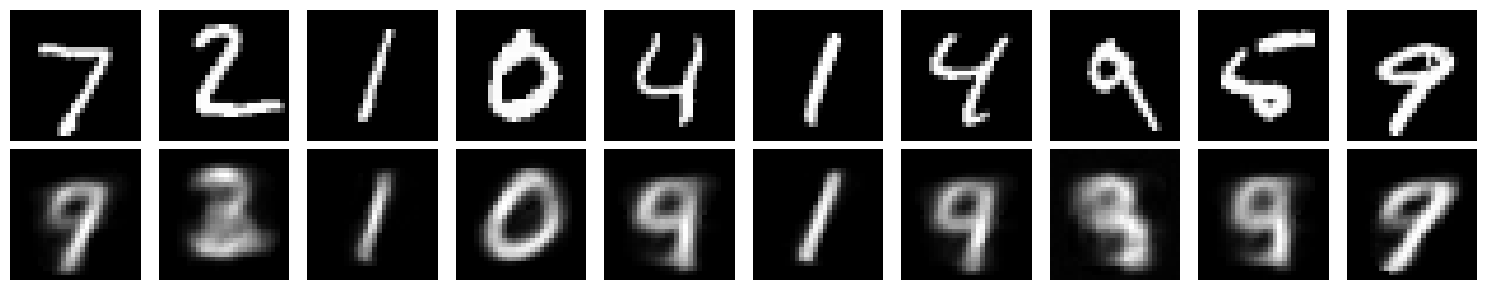

In [25]:
ae.eval()
images_test, labels_test = next(iter(test_loader))
with torch.no_grad():
    reconstructions = ae(images_test[:10].to(device)).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(images_test[i, 0], cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i, 0], cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Originale")
axes[1, 0].set_ylabel("Reconstruite")
plt.tight_layout()
plt.show()

### Etape 4 - Visualiser l'espace latent

Chaque image devient un point `(z1, z2)`. Les couleurs indiquent les labels uniquement pour lire le graphique ; ils n'ont pas servi a entrainer l'autoencodeur.

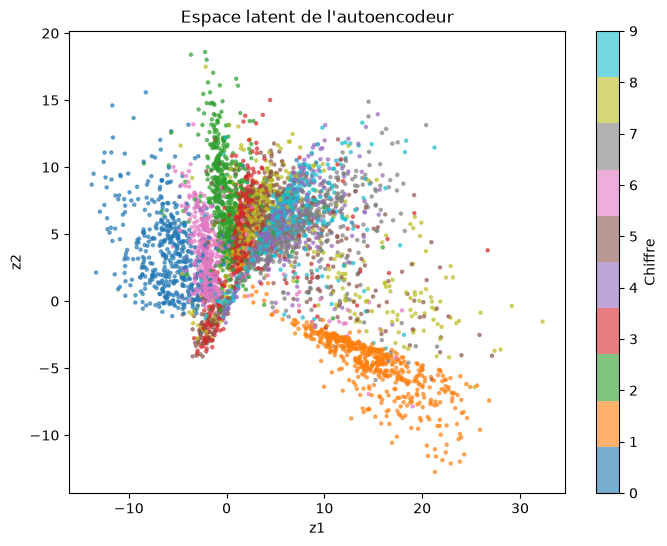

In [26]:
latent_points, latent_labels = [], []
ae.eval()
with torch.no_grad():
    for x, y in test_loader:
        latent_points.append(ae.encode(x.to(device)).cpu())
        latent_labels.append(y)

z_all = torch.cat(latent_points)[:5000]
y_all = torch.cat(latent_labels)[:5000]
plt.figure(figsize=(8, 6))
plt.scatter(z_all[:, 0], z_all[:, 1], c=y_all, cmap="tab10", s=5, alpha=0.6)
plt.colorbar(ticks=range(10), label="Chiffre")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent de l'autoencodeur")
plt.show()

## Questions et reponses rapides

**Pourquoi les labels ne sont-ils pas necessaires ?** La cible est l'image elle-meme : `x -> x_hat`, et non une classe `y`.

**A quoi sert l'espace latent ?** Il contient une representation compacte de l'image ; ici 784 pixels deviennent seulement 2 nombres.

**Que signifie une loss faible ?** L'image reconstruite est proche de l'image originale pixel par pixel.

**Pourquoi un autoencodeur classique ne genere-t-il pas toujours une bonne image avec un point aleatoire ?** Son espace latent n'est pas force a suivre une distribution reguliere. Cette limite motive le VAE de la Partie III.

# Partie III - Variational Autoencoder (VAE)

Un VAE apprend une distribution latente reguliere. Il peut donc reconstruire une image et generer une nouvelle image en partant directement d'un bruit gaussien.

### Etape 1 - Comprendre le principe

Un autoencodeur classique produit un seul vecteur `z`. Un VAE produit deux vecteurs : `mu`, la moyenne, et `logvar`, le logarithme de la variance. Ils definissent une distribution dans laquelle on echantillonne `z`.

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


vae = VAE(latent_dim=2).to(device)
print(vae)

### Etape 2 - Reparametrisation

On ecrit `z = mu + sigma * epsilon`, avec `epsilon` tire dans une loi normale standard. Cette astuce permet de conserver la retropropagation malgre l'echantillonnage aleatoire.

In [ ]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    reconstruction_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss, kl_loss

### Etape 3 - Fonction de perte

La perte contient deux objectifs : `reconstruction_loss` garde des images fidele aux originales, tandis que `kl_loss` rapproche l'espace latent d'une loi normale `N(0, I)`. `beta` regle l'importance de cette regularisation.

In [ ]:
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=10, beta=1.0):
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        total_reconstruction = 0.0
        total_kl = 0.0

        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, reconstruction, kl = vae_loss(x_hat, x, mu, logvar, beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_reconstruction += reconstruction.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss={total_loss / n:.2f} | "
            f"Rec={total_reconstruction / n:.2f} | "
            f"KL={total_kl / n:.2f}"
        )

train_vae(vae, train_loader, epochs=10, beta=1.0)

### Etape 4 - Reconstruire des images

On compare les images originales aux images reconstruites par le VAE. La reconstruction peut etre un peu floue, car le modele doit respecter en meme temps la contrainte KL.

In [ ]:
vae.eval()
x_test, _ = next(iter(test_loader))
x_test = x_test[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x_test)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x_test[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Originale")
axes[1, 0].set_ylabel("VAE")
plt.tight_layout()
plt.show()

### Etape 5 - Visualiser l'espace latent

On affiche `mu`, le centre de la distribution latente de chaque image. Les labels servent seulement a colorer le graphique, pas a entrainer le VAE.

In [ ]:
vae.eval()
means, labels_latent = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, _ = vae.encode(x.to(device))
        means.append(mu.cpu())
        labels_latent.append(y)

means = torch.cat(means).numpy()
labels_latent = torch.cat(labels_latent).numpy()
plt.figure(figsize=(8, 6))
scatter = plt.scatter(means[:, 0], means[:, 1], c=labels_latent, s=4, cmap="tab10")
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter, label="Chiffre")
plt.show()

### Etape 6 - Generer de nouvelles images

Le VAE permet de generer sans image d'entree : on tire `z` dans `N(0, I)`, puis le decodeur transforme `z` en nouvelle image.

In [ ]:
vae.eval()
with torch.no_grad():
    z = torch.randn(20, 2, device=device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for sample, ax in zip(samples, axes.flat):
    ax.imshow(sample.squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Nouveaux chiffres generes par le VAE")
plt.tight_layout()
plt.show()

## Questions et reponses rapides

**1. Que produisent `mu` et `logvar` ?**  
`mu` donne le centre de la distribution latente et `logvar` controle sa dispersion.

**2. Pourquoi utiliser la reparametrisation ?**  
Elle conserve l'aleatoire de l'echantillonnage tout en permettant a l'erreur de remonter jusqu'a l'encodeur.

**3. A quoi sert la perte KL ?**  
Elle regularise l'espace latent pour le rapprocher d'une loi normale standard, ce qui rend les tirages aleatoires utiles.

**4. Que se passe-t-il si `beta` augmente ?**  
La regularisation devient plus forte : l'espace latent est plus regulier, mais les reconstructions peuvent devenir moins precises.

**5. Quelle est la difference avec l'autoencodeur classique ?**  
L'autoencodeur classique compresse vers un point fixe ; le VAE apprend une distribution et peut generer en echantillonnant `z`.

**6. Pourquoi les labels ne sont-ils pas necessaires ?**  
Le VAE apprend a reconstruire `x` et a organiser son espace latent. Les labels servent uniquement a colorer les graphiques.